# 05 — OpenCV Filtering & Convolution

This notebook covers image smoothing, kernels, convolution, Gaussian blur, median filtering, bilateral filtering, sharpening, and edge-preserving smoothing.

**Goal:** understand what a filter does to neighboring pixels and how OpenCV implements common filters.

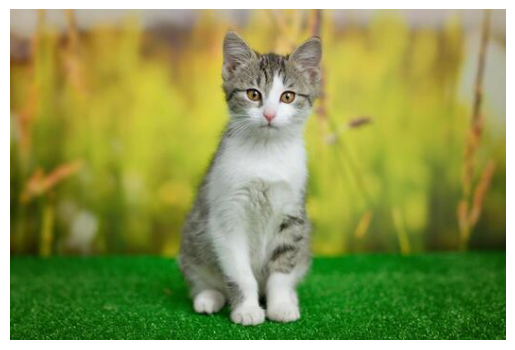

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

image = cv2.imread("cat.jpg")
if image is None:
    raise FileNotFoundError("cat.jpg not found")
rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
plt.imshow(rgb)
plt.axis("off")
plt.show()

## 1. Why filtering?

A filter computes a new pixel from nearby pixels.

Typical uses: **noise reduction, smoothing, sharpening, and feature extraction**.

## 2. Kernel

A kernel is a small matrix that slides across an image.

For a 3×3 kernel, each output pixel is calculated from its surrounding 3×3 neighborhood.

In [2]:
kernel = np.ones((3, 3), dtype=np.float32) / 9
print(kernel)

[[0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]
 [0.11111111 0.11111111 0.11111111]]


## 3. Convolution — the math

For an image $I$ and kernel $K$:

$$O(x,y)=\sum_i\sum_j K(i,j)I(x-i,y-j)$$

The kernel weights neighboring pixels, and their weighted sum becomes the output pixel.

For an averaging kernel:

$$K=\frac{1}{9}\begin{bmatrix}1&1&1\\1&1&1\\1&1&1\end{bmatrix}$$

so the output is the average of the 9 neighboring pixels.

## 4. `cv2.filter2D()`

**Syntax:** `cv2.filter2D(src, ddepth, kernel)`

- `src` → input image
- `ddepth` → output depth; `-1` keeps the input depth
- `kernel` → filtering kernel
- **Return:** filtered image

[[0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]
 [0.04 0.04 0.04 0.04 0.04]]


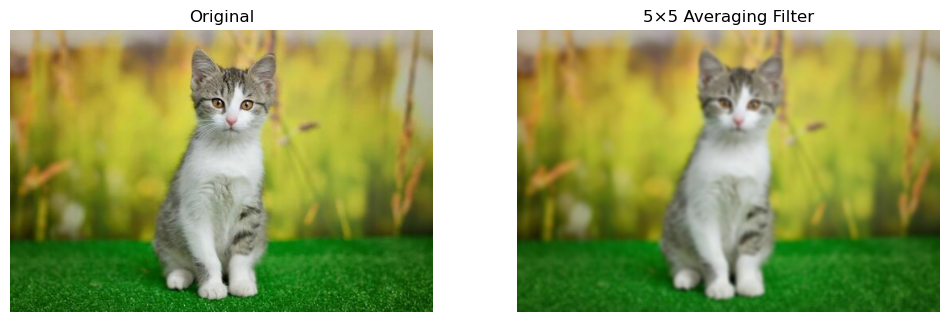

In [16]:
blur_kernel = np.ones((5, 5), dtype=np.float32) / 25

print(blur_kernel)

filtered = cv2.filter2D(image, -1, blur_kernel)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].imshow(rgb); axes[0].set_title("Original")

axes[1].imshow(cv2.cvtColor(filtered, cv2.COLOR_BGR2RGB)); axes[1].set_title("5×5 Averaging Filter")

for ax in axes: ax.axis("off")
plt.show()

## 5. Mean / box filter

`cv2.blur()` applies an averaging filter.

**Syntax:** `cv2.blur(src, ksize)`

Larger kernels produce stronger smoothing but also remove more detail.

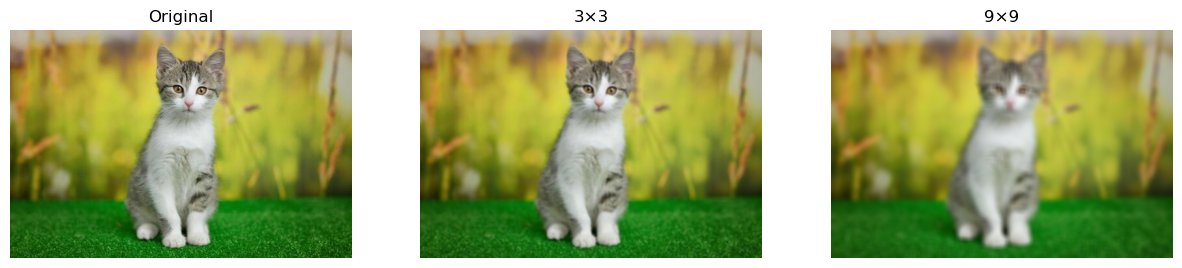

In [4]:
blur3 = cv2.blur(image, (3, 3))
blur9 = cv2.blur(image, (9, 9))
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, img, title in zip(axes, [image, blur3, blur9], ["Original", "3×3", "9×9"]):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax.set_title(title); ax.axis("off")
plt.show()

## 6. Gaussian blur

Gaussian filtering gives higher weight to pixels near the center.

**Syntax:** `cv2.GaussianBlur(src, ksize, sigmaX)`

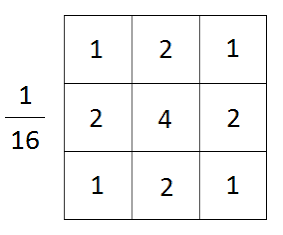

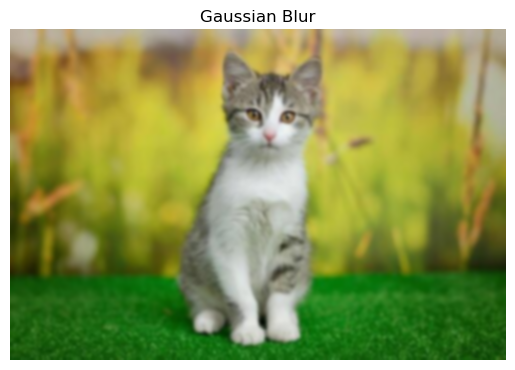

In [5]:
gaussian = cv2.GaussianBlur(image, (7, 7), 0)
plt.imshow(cv2.cvtColor(gaussian, cv2.COLOR_BGR2RGB))
plt.title("Gaussian Blur"); plt.axis("off"); plt.show()

## 7. Gaussian function — the math

A 2D Gaussian is:

$$G(x,y)=\frac{1}{2\pi\sigma^2}e^{-\frac{x^2+y^2}{2\sigma^2}}$$

Pixels close to the kernel center receive larger weights.

Increasing $\sigma$ spreads the Gaussian and produces stronger smoothing.

In [6]:
def gaussian_kernel(size, sigma):
    ax = np.arange(-(size // 2), size // 2 + 1)
    xx, yy = np.meshgrid(ax, ax)
    kernel = np.exp(-(xx**2 + yy**2) / (2 * sigma**2))
    kernel /= kernel.sum()
    return kernel

gk = gaussian_kernel(5, 1.0)
print(gk)
print("Kernel sum:", gk.sum())

[[0.00296902 0.01330621 0.02193823 0.01330621 0.00296902]
 [0.01330621 0.0596343  0.09832033 0.0596343  0.01330621]
 [0.02193823 0.09832033 0.16210282 0.09832033 0.02193823]
 [0.01330621 0.0596343  0.09832033 0.0596343  0.01330621]
 [0.00296902 0.01330621 0.02193823 0.01330621 0.00296902]]
Kernel sum: 1.0


## 8. Median filter

`cv2.medianBlur()` replaces each pixel with the **median** of its neighborhood.

It is especially effective against **salt-and-pepper noise**.

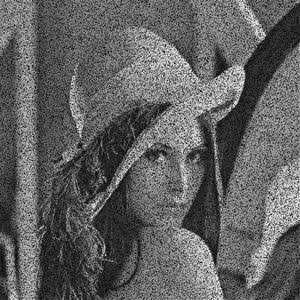

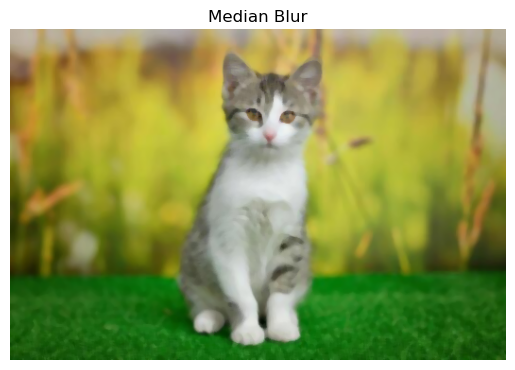

In [7]:
median = cv2.medianBlur(image, 5)
plt.imshow(cv2.cvtColor(median, cv2.COLOR_BGR2RGB))
plt.title("Median Blur"); plt.axis("off"); plt.show()

## 9. Mean vs Gaussian vs Median

- **Mean:** simple averaging; can blur edges strongly.
- **Gaussian:** weighted smoothing; generally more natural.
- **Median:** excellent for impulse noise and preserves edges better.

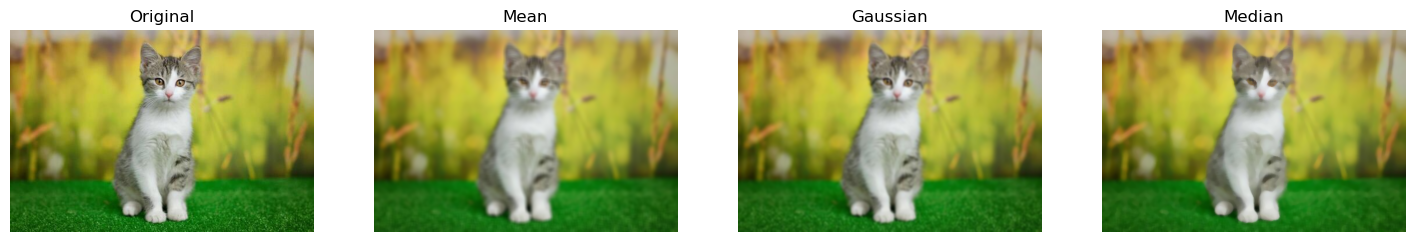

In [8]:
mean = cv2.blur(image, (7, 7))
gaussian = cv2.GaussianBlur(image, (7, 7), 0)
median = cv2.medianBlur(image, 7)
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, img, title in zip(axes, [image, mean, gaussian, median], ["Original", "Mean", "Gaussian", "Median"]):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax.set_title(title); ax.axis("off")
plt.show()

## 10. Bilateral filtering

`cv2.bilateralFilter()` smooths similar pixels while trying to preserve strong edges.

**Syntax:** `cv2.bilateralFilter(src, d, sigmaColor, sigmaSpace)`

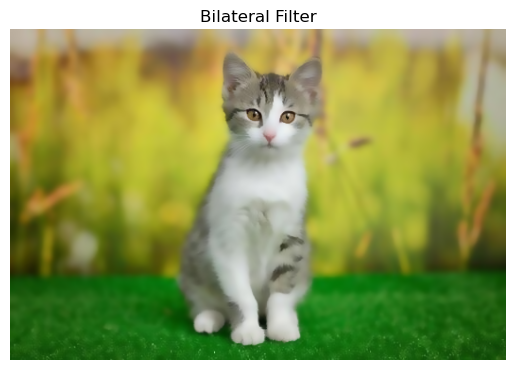

In [ ]:
bilateral = cv2.bilateralFilter(image, d=9, sigmaColor=75, sigmaSpace=75)
# src
# diameter each pixel neighborhood
# filter sigma in color space
# filter sigma in the coordinate space

# sigma (σ) controls the width of a bell curve, which decides how much weight to give to pixels that are farther away.

plt.imshow(cv2.cvtColor(bilateral, cv2.COLOR_BGR2RGB))
plt.title("Bilateral Filter"); plt.axis("off"); plt.show()

## 11. Bilateral filter intuition

Bilateral filtering considers both **spatial distance** and **intensity/color difference**.

So it can smooth within regions while preserving important edges.

## 12. Add noise

Filtering becomes easier to understand when we intentionally corrupt an image with noise.

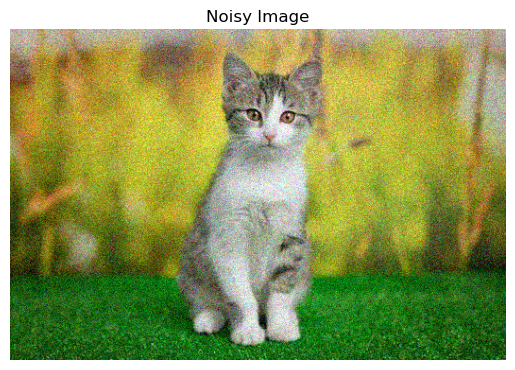

In [10]:
noise = np.random.normal(0, 25, image.shape).astype(np.float32)
noisy = np.clip(image.astype(np.float32) + noise, 0, 255).astype(np.uint8)
plt.imshow(cv2.cvtColor(noisy, cv2.COLOR_BGR2RGB))
plt.title("Noisy Image"); plt.axis("off"); plt.show()

## 13. Compare filters on noisy image

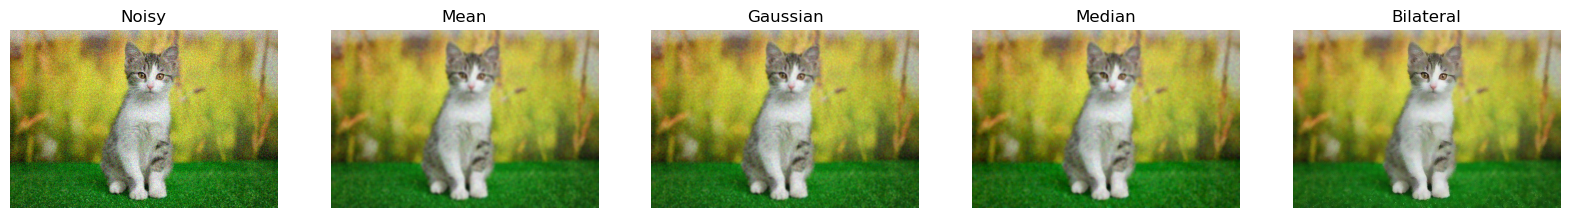

In [11]:
mean_noisy = cv2.blur(noisy, (5, 5))
gaussian_noisy = cv2.GaussianBlur(noisy, (5, 5), 0)
median_noisy = cv2.medianBlur(noisy, 5)
bilateral_noisy = cv2.bilateralFilter(noisy, 9, 75, 75)
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
for ax, img, title in zip(axes, [noisy, mean_noisy, gaussian_noisy, median_noisy, bilateral_noisy], ["Noisy", "Mean", "Gaussian", "Median", "Bilateral"]):
    ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB)); ax.set_title(title); ax.axis("off")
plt.show()

## 14. Sharpening with a kernel

A sharpening kernel emphasizes the center pixel and subtracts neighboring pixels.

$$K=\begin{bmatrix}0&-1&0\\-1&5&-1\\0&-1&0\end{bmatrix}$$

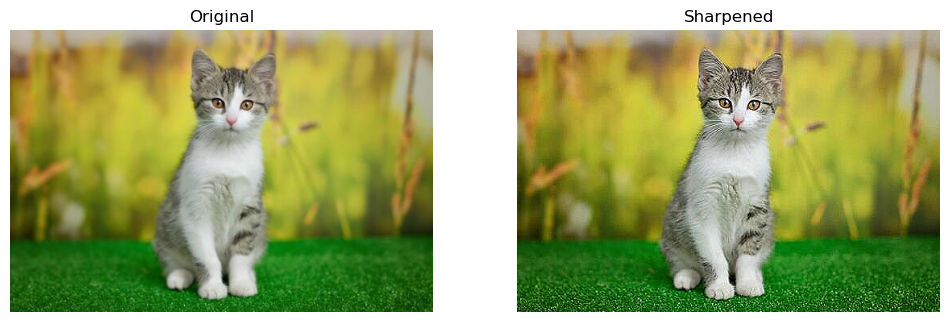

In [12]:
sharpen_kernel = np.array([[0, -1, 0], [-1, 5, -1], [0, -1, 0]], dtype=np.float32)
sharpened = cv2.filter2D(image, -1, sharpen_kernel)
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(rgb); axes[0].set_title("Original")
axes[1].imshow(cv2.cvtColor(sharpened, cv2.COLOR_BGR2RGB)); axes[1].set_title("Sharpened")
for ax in axes: ax.axis("off")
plt.show()

## 15. Laplacian sharpening

The Laplacian detects rapid intensity changes.

A common sharpening idea is:

$$I_{sharp}=I-\alpha\nabla^2 I$$

where $\nabla^2 I$ is the Laplacian of the image.

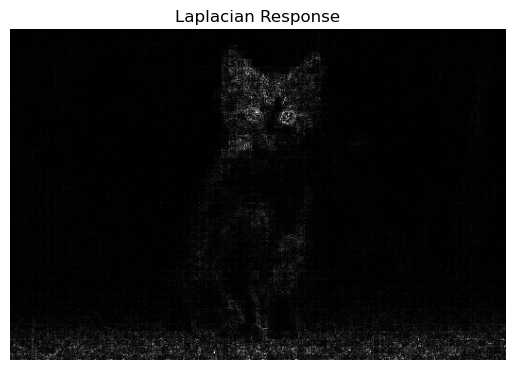

In [13]:
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
lap = cv2.Laplacian(gray, cv2.CV_64F)
lap_abs = cv2.convertScaleAbs(lap)
plt.imshow(lap_abs, cmap="gray")
plt.title("Laplacian Response"); plt.axis("off"); plt.show()

## 16. Kernel size

For filters such as Gaussian and median blur, the kernel size controls the neighborhood.

For most OpenCV blur functions, use positive odd values such as `3`, `5`, `7`, etc.

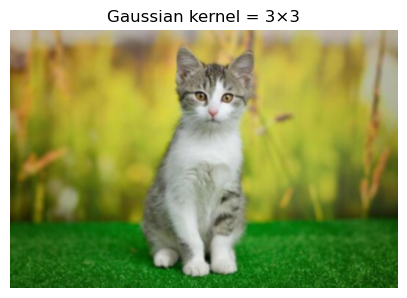

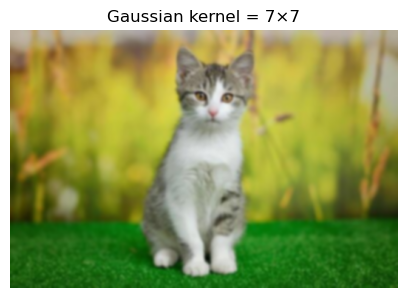

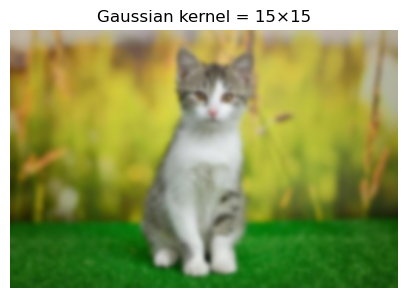

In [14]:
for k in [3, 7, 15]:
    result = cv2.GaussianBlur(image, (k, k), 0)
    plt.figure(figsize=(5, 4))
    plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    plt.title(f"Gaussian kernel = {k}×{k}")
    plt.axis("off")
    plt.show()

## 17. Border handling

When a kernel reaches the image boundary, OpenCV must determine what exists outside the image.

Common modes include `BORDER_CONSTANT`, `BORDER_REPLICATE`, `BORDER_REFLECT`, and `BORDER_REFLECT_101`.

{'CONSTANT': 0, 'REPLICATE': 1, 'REFLECT': 2, 'REFLECT_101': 4}


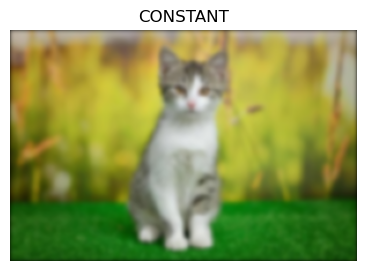

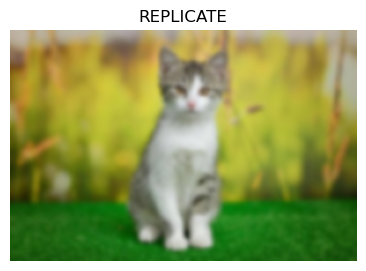

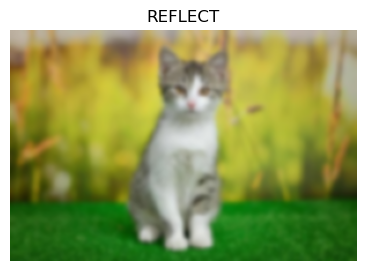

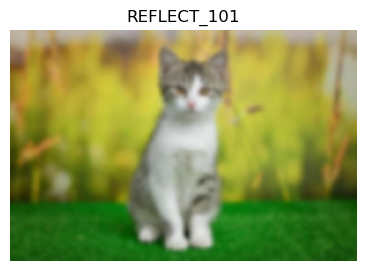

In [17]:
small = cv2.resize(image, (300, 200))
border_modes = {"CONSTANT": cv2.BORDER_CONSTANT, "REPLICATE": cv2.BORDER_REPLICATE, "REFLECT": cv2.BORDER_REFLECT, "REFLECT_101": cv2.BORDER_REFLECT_101}
print(border_modes)
for name, mode in border_modes.items():
    result = cv2.GaussianBlur(small, (9, 9), 0, borderType=mode)
    plt.figure(figsize=(5, 3))
    plt.imshow(cv2.cvtColor(result, cv2.COLOR_BGR2RGB))
    plt.title(name); plt.axis("off"); plt.show()

## 18. Important parameter cheat sheet

| Function | Important parameters |
|---|---|
| `filter2D()` | `ddepth`, `kernel` |
| `blur()` | `ksize` |
| `GaussianBlur()` | `ksize`, `sigmaX`, `sigmaY` |
| `medianBlur()` | `ksize` |
| `bilateralFilter()` | `d`, `sigmaColor`, `sigmaSpace` |
| `Laplacian()` | `ddepth`, `ksize` |

**Rule:** larger neighborhoods generally produce stronger smoothing, but also remove more fine detail.

## 19. When to use which filter?

| Problem | Good starting choice |
|---|---|
| General smoothing | Gaussian |
| Simple averaging | Mean / box |
| Salt-and-pepper noise | Median |
| Smooth while preserving edges | Bilateral |
| Increase local sharpness | Sharpening kernel |
| Detect rapid intensity changes | Laplacian |